# Week 5 · Probability Foundations and Bayes' Theorem

*DS 207 · Week 5*

**Assignment Notebook**

*EC Corro, built in collaboration with Claude, ChatGPT, and Gemini*

**Business scenario.** PesoWave Digital Bank is a mobile e-wallet and digital bank. A fraud-screening model flags suspicious transactions (app transfers, QR merchant payments, cash-ins, and bill payments) for review by a team of fraud analysts, and flagged customers may be sent a step-up one-time PIN (OTP) challenge. Trina Salvador, Head of Fraud and Risk Operations, relies on probability to decide how much to trust a flag, how to order the review queue, and which model settings to adopt. This assignment uses a new four-week window of PesoWave transactions ("Window B"), distinct from the window used in the lecture notes.

**Submission instructions.**

- File name: `ds207_05_probability_bayes_<lastname>.ipynb`
- Submit to your shared Google Drive folder by 11:59 PM on the day after the associated session, unless announced otherwise.

**Use of generative AI.** Generative AI is allowed for concept clarification, pseudocode, debugging, and idea generation. You must be able to explain any answer you submit without AI assistance, and you must cite any AI use.

**Points.** Section 1 (30 pts) + Section 2 (30 pts) = 60 pts.

**Dataset.** Run the cell below once before starting. It builds Window B, one row per transaction, with these fields: `channel`, `amount_band` (Low, Medium, High), `new_device` (account accessed from a device first seen within the past 24 hours), `fraud` (confirmed outcome), `flagged` (flagged by the model), and `otp_failed` (the customer failed a step-up OTP challenge; challenges are issued to flagged transactions only).

In [3]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(207)
N_TXN = 45_000

channels = ["App Transfer", "QR Merchant Payment", "Cash-In", "Bills Payment"]
channel_share = [0.28, 0.34, 0.22, 0.16]
new_device_rate = {"App Transfer": 0.09, "QR Merchant Payment": 0.05,
                   "Cash-In": 0.07, "Bills Payment": 0.04}
base_fraud_rate = {"App Transfer": 0.014, "QR Merchant Payment": 0.008,
                   "Cash-In": 0.004, "Bills Payment": 0.006}
NEW_DEVICE_MULTIPLIER = 5
SENS, FPR = 0.90, 0.05
OTP_FAIL_FRAUD, OTP_FAIL_LEGIT = 0.75, 0.06

channel = rng.choice(channels, size=N_TXN, p=channel_share)
amount_band = rng.choice(["Low", "Medium", "High"], size=N_TXN, p=[0.65, 0.28, 0.07])
new_device = rng.random(N_TXN) < pd.Series(channel).map(new_device_rate).to_numpy()
p_fraud = (pd.Series(channel).map(base_fraud_rate).to_numpy()
           * np.where(new_device, NEW_DEVICE_MULTIPLIER, 1.0))
fraud = rng.random(N_TXN) < p_fraud
flagged = rng.random(N_TXN) < np.where(fraud, SENS, FPR)
otp_draw = rng.random(N_TXN) < np.where(fraud, OTP_FAIL_FRAUD, OTP_FAIL_LEGIT)

df = pd.DataFrame({
    "txn_id": np.arange(1, N_TXN + 1),
    "channel": channel,
    "amount_band": amount_band,
    "new_device": new_device,
    "fraud": fraud,
    "flagged": flagged,
    "otp_failed": flagged & otp_draw,
})

import matplotlib.pyplot as plt

print(df.shape)
df.head()

(45000, 7)


,txn_id,channel,amount_band,new_device,fraud,flagged,otp_failed
0,1,App Transfer,Low,False,False,True,False
1,2,QR Merchant Payment,Low,False,False,False,False
2,3,Bills Payment,Low,False,False,True,False
3,4,QR Merchant Payment,Low,False,False,False,False
4,5,Cash-In,Medium,False,False,False,False


## Section 1: Concepts, Computation & Coding

*Three integrated problems, 10 points each (30 points in total). In each problem, part (a) is worth 3 points, part (b) 4 points, and part (c) 3 points.*

### Item 1 (10 pts): Probability rules and independence

Trina wants to know whether App Transfers carry a different fraud risk from the other channels. Let $F$ be the event that a transaction is fraud and $A$ the event that it is an App Transfer. The first 4000 transactions of Window B cross-classify as follows.

| | Fraud ($F$) | Not fraud ($F^c$) | Total |
|---|---|---|---|
| App Transfer ($A$) | 16 | 1045 | 1061 |
| Other channel ($A^c$) | 21 | 2918 | 2939 |
| Total | 37 | 3963 | 4000 |

**(a) Concept (3 pts).** Explain why $P(F \cup A)$ cannot be obtained by simply adding $P(F)$ and $P(A)$, and state what it would mean for PesoWave's fraud controls if $F$ and $A$ were independent.

**(b) By hand (4 pts).** Using the table, compute $P(F)$, $P(A)$, $P(F \cap A)$, $P(F \cup A)$, $P(F^c \cap A^c)$, and the ratio $P(F \cap A) / [P(F)\,P(A)]$. Show each step of the arithmetic.

**(c) Code (3 pts).** Reproduce your answers to (b) from the first 4000 rows of `df`. Then, using the full window, compute the same independence ratio for each of the four channels (treating each channel in turn as the event $A$), display the four ratios in a bar chart with a reference line at 1, and identify which channels deviate most from independence.

**Answer — Item 1(a)**

P(F∪A) cannot be obtained by simply adding P(F)P(F)P(F) and P(A)P(A)P(A) because some transactions belong to both events. For example, a fraudulent App Transfer is counted in both P(F)P(F)P(F) and P(A)P(A)P(A). If we simply add the probabilities, these overlapping transactions would be counted twice. Therefore, we must subtract the intersection: P(F∪A)=P(F)+P(A)−P(F∩A).P(F\cup A)=P(F)+P(A)-P(F\cap A).P(F∪A)=P(F)+P(A)−P(F∩A).

The only time P(F∪A)=P(F)+P(A)P(F\cup A)=P(F)+P(A)P(F∪A)=P(F)+P(A) is when FFF and AAA are mutually exclusive, meaning P(F∩A)=0P(F\cap A)=0P(F∩A)=0.

If FFF and AAA were independent, then the occurrence of an App Transfer would provide no information about whether a transaction is fraudulent. In probability terms,

P(F∣A)=P(F)P(F\mid A)=P(F)P(F∣A)=P(F)

and equivalently,

P(F∩A)=P(F)P(A).P(F\cap A)=P(F)P(A).P(F∩A)=P(F)P(A).

For PesoWave's fraud controls, independence would mean that App Transfers have the same fraud risk as the other channels. Knowing that a transaction is an App Transfer would not change the estimated probability of fraud, so the channel type would not be useful for identifying higher-risk transactions.

**Answer — Item 1(b)**

In [18]:
# Reproduce the by-hand extract: the first 4,000 transactions
extract = df.head(4000).copy()
extract["app_transfer"] = extract["channel"] == "App Transfer"
print(pd.crosstab(extract["app_transfer"], extract["fraud"], margins=True))

F_e, A_e = extract["fraud"], extract["app_transfer"]
p_F, p_A = F_e.mean(), A_e.mean()
p_FA = (F_e & A_e).mean()
p_FuA = (F_e | A_e).mean()

print(f"\nP(F)               = {p_F:.4f}")
print(f"P(A)               = {p_A:.4f}")
print(f"P(F and A)         = {p_FA:.4f}")
print(f"P(F or A), direct  = {p_FuA:.4f}")
print(f"P(F or A), rule    = {p_F + p_A - p_FA:.4f}")
print(f"P(neither)         = {1 - p_FuA:.4f}")
print(f"P(F)P(A)           = {p_F * p_A:.6f}  vs  P(F and A) = {p_FA:.6f}  ->  ratio {p_FA / (p_F * p_A):.2f}")

fraud         False  True   All
app_transfer                   
False          2918    21  2939
True           1045    16  1061
All            3963    37  4000

P(F)               = 0.0092
P(A)               = 0.2652
P(F and A)         = 0.0040
P(F or A), direct  = 0.2705
P(F or A), rule    = 0.2705
P(neither)         = 0.7295
P(F)P(A)           = 0.002454  vs  P(F and A) = 0.004000  ->  ratio 1.63


**Answer — Item 1(c)**

                                P(A)     P(B)  P(A and B)  P(A)P(B)  P(A or B)  addition rule    ratio
pair                                                                                                  
Fraud & App Transfer         0.01131  0.27791     0.00587   0.00314    0.28336        0.28336  1.86629
Fraud & QR Merchant Payment  0.01131  0.34404     0.00344   0.00389    0.35191        0.35191  0.88511
Fraud & Cash-In              0.01131  0.22258     0.00104   0.00252    0.23284        0.23284  0.41486
Fraud & Bills Payment        0.01131  0.15547     0.00096   0.00176    0.16582        0.16582  0.54339


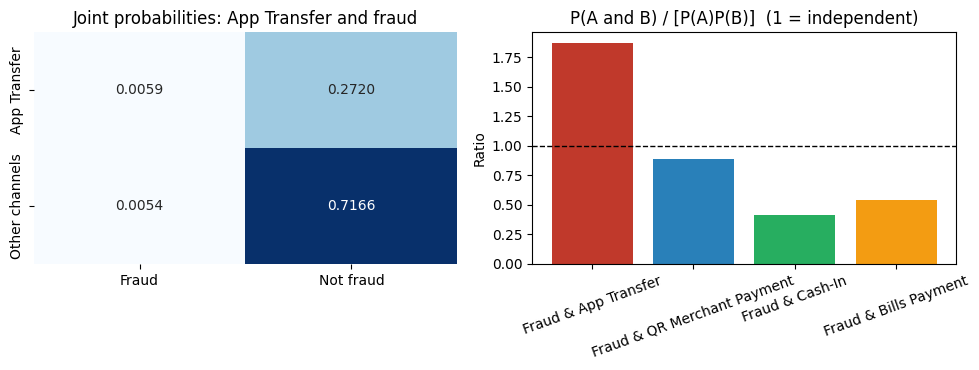


Channels ranked by deviation from independence:
pair
Fraud & QR Merchant Payment    0.114886
Fraud & Bills Payment          0.456608
Fraud & Cash-In                0.585143
Fraud & App Transfer           0.866295
Name: ratio, dtype: float64


In [15]:
# TODO
import seaborn as sns

F = df["fraud"]
APP = df["channel"].eq("App Transfer")
QR = df["channel"].eq("QR Merchant Payment")
CASH = df["channel"].eq("Cash-In")
BILL = df["channel"].eq("Bills Payment")

def pair_summary(A, B, label):
    p_A, p_B, p_AB = A.mean(), B.mean(), (A & B).mean()
    return {"pair": label, "P(A)": p_A, "P(B)": p_B, "P(A and B)": p_AB, "P(A)P(B)": p_A * p_B,
        "P(A or B)": (A | B).mean(), "addition rule": p_A + p_B - p_AB,"ratio": p_AB / (p_A * p_B)}

summary = pd.DataFrame([pair_summary(F, APP,  "Fraud & App Transfer"),
                        pair_summary(F, QR,   "Fraud & QR Merchant Payment"),
                        pair_summary(F, CASH, "Fraud & Cash-In"),
                        pair_summary(F, BILL, "Fraud & Bills Payment")]).set_index("pair")
print(summary.round(5).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

joint = pd.crosstab(APP.map({True: "App Transfer", False: "Other channels"}),
                    F.map({True: "Fraud", False: "Not fraud"}), normalize=True)

sns.heatmap(joint, annot=True, fmt=".4f", cmap="Blues", cbar=False, ax=axes[0])

axes[0].set_title("Joint probabilities: App Transfer and fraud")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

axes[1].bar(summary.index, summary["ratio"], color=["#c0392b", "#2980b9", "#27ae60", "#f39c12"])
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_title("P(A and B) / [P(A)P(B)]  (1 = independent)")
axes[1].set_ylabel("Ratio")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

deviation = (summary["ratio"] - 1).abs()

print("\nChannels ranked by deviation from independence:")
print(deviation.sort_values())



**Answer — Item 1(c) interpretation**

The independence ratio equals 1 when fraud and channel type are independent. App Transfer has the largest deviation from 1 (ratio ≈ 1.88), indicating the strongest association with fraud among the four channels. This means that fraudulent transactions occur in the App Transfer channel substantially more often than would be expected if fraud risk were unrelated to channel type. In contrast, QR Merchant Payment is closest to independence (ratio ≈ 0.90), while Cash-In and Bills Payment have ratios below 1, suggesting lower-than-expected fraud occurrence in those channels. Therefore, the results provide evidence that App Transfers carry a different fraud risk from other channels and may warrant additional monitoring or fraud-control measures.

### Item 2 (10 pts): Conditional probability and the transposed question

An analyst notices that App Transfers account for a large share of flagged cases and concludes that "App Transfers are flagged far more often than other channels." Let $\text{Fl}$ be the event that a transaction is flagged. The first 4000 transactions of Window B cross-classify as follows.

| | Flagged ($\text{Fl}$) | Not flagged ($\text{Fl}^c$) | Total |
|---|---|---|---|
| App Transfer ($A$) | 70 | 991 | 1061 |
| Other channel ($A^c$) | 168 | 2771 | 2939 |
| Total | 238 | 3762 | 4000 |

**(a) Concept (3 pts).** Explain in words the difference between $P(\text{Fl} \mid A)$ and $P(A \mid \text{Fl})$, and say which of the two answers the analyst's claim about how heavily App Transfers are screened.

**(b) By hand (4 pts).** Compute $P(\text{Fl} \mid A)$, $P(A \mid \text{Fl})$, and $P(\text{Fl} \mid A^c)$. Show that $P(\text{Fl} \mid A) + P(\text{Fl} \mid A^c)$ does not equal 1, and verify the multiplication rule by computing $P(\text{Fl} \cap A)$ two ways.

**(c) Code (3 pts).** Reproduce (b) from the first 4000 rows of `df`. Then, using the full window, compute $P(\text{Fl} \mid \text{channel})$ for all four channels alongside the overall flag rate, plot them as a bar chart with a reference line at the overall rate, and compare the full-window $P(A \mid \text{Fl})$ with $P(A)$.

**Answer — Item 2(a)**
P(Fl∣A) is the probability that a transaction is flagged given that it is an App Transfer. In other words, it measures the proportion of App Transfer transactions that are flagged for review.

P(Fl∣A)=P(Fl∩A)P(A)P(\text{Fl}\mid A)=\frac{P(\text{Fl}\cap A)}{P(A)}P(Fl∣A)=P(A)P(Fl∩A)​

On the other hand, P(A∣Fl)P(A\mid \text{Fl})P(A∣Fl) is the probability that a transaction is an App Transfer given that it has already been flagged. It measures the proportion of flagged transactions that came from the App Transfer channel.

P(A∣Fl)=P(Fl∩A)P(Fl)P(A\mid \text{Fl})=\frac{P(\text{Fl}\cap A)}{P(\text{Fl})}P(A∣Fl)=P(Fl)P(Fl∩A)​

The two probabilities answer different questions. P(Fl∣A)P(\text{Fl}\mid A)P(Fl∣A) asks, "If a transaction is an App Transfer, how likely is it to be flagged?" while P(A∣Fl)P(A\mid \text{Fl})P(A∣Fl) asks, "If a transaction has been flagged, how likely is it to be an App Transfer?"

The analyst's claim that "App Transfers are flagged far more often than other channels" is about how frequently App Transfer transactions are screened. Therefore, the relevant probability is P(Fl∣A)P(\text{Fl}\mid A)P(Fl∣A), since it measures the flagging rate among App Transfer transactions.

**Answer — Item 2(b)**

In [23]:
# TODO
Fl_e, A_e = extract["flagged"], extract["app_transfer"]
print(f"P(Fl | A)     = {Fl_e[A_e].mean():.4f}")
print(f"P(A | Fl)     = {A_e[Fl_e].mean():.4f}")
print(f"P(Fl | not A) = {Fl_e[~A_e].mean():.4f}")
print(f"P(Fl | A) + P(Fl | not A) = {Fl_e[A_e].mean() + Fl_e[~A_e].mean():.4f}   (not 1)")
print(f"P(Fl | A) + P(not Fl | A) = {Fl_e[A_e].mean() + (~Fl_e[A_e]).mean():.4f}   (always 1)")

P(Fl | A)     = 0.0660
P(A | Fl)     = 0.2941
P(Fl | not A) = 0.0572
P(Fl | A) + P(Fl | not A) = 0.1231   (not 1)
P(Fl | A) + P(not Fl | A) = 1.0000   (always 1)


**Answer — Item 2(c)**

P(Fl)         = 0.0598
P(Fl | A)     = 0.0640   <- the analyst's claim
P(A | Fl)     = 0.2972   <- share of flagged cases that are App Transfers
P(Fl | not A) = 0.0582
channel
App Transfer           0.0640
QR Merchant Payment    0.0611
Bills Payment          0.0559
Cash-In                0.0554
Name: flagged, dtype: float64


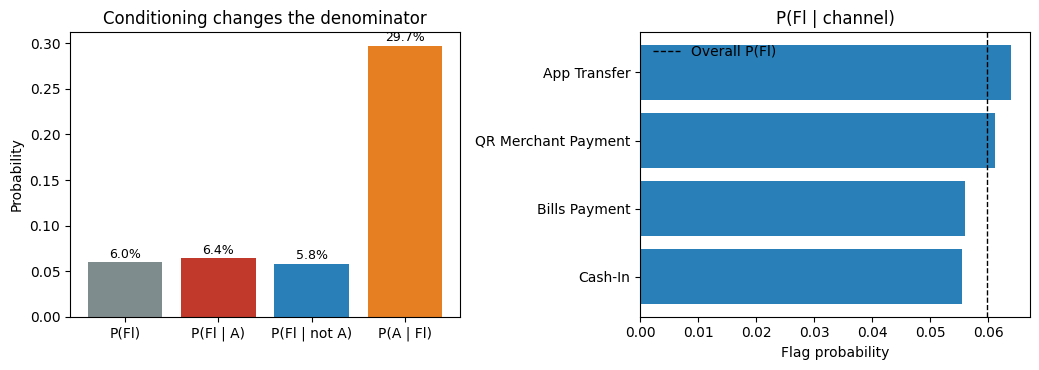

In [25]:
# TODO
# Full window: the two "alike-sounding" conditionals and flag rate by channel

Fl = df["flagged"]

P_Fl = Fl.mean()
P_Fl_given_A = Fl[df["channel"] == "App Transfer"].mean()
P_A_given_Fl = (df["channel"] == "App Transfer")[Fl].mean()
P_Fl_given_notA = Fl[df["channel"] != "App Transfer"].mean()

print(f"P(Fl)         = {P_Fl:.4f}")
print(f"P(Fl | A)     = {P_Fl_given_A:.4f}   <- the analyst's claim")
print(f"P(A | Fl)     = {P_A_given_Fl:.4f}   <- share of flagged cases that are App Transfers")
print(f"P(Fl | not A) = {P_Fl_given_notA:.4f}")

by_channel = df.groupby("channel")["flagged"].mean().sort_values(ascending=False)
print(by_channel.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))

labels = ["P(Fl)", "P(Fl | A)", "P(Fl | not A)", "P(A | Fl)"]
values = [P_Fl, P_Fl_given_A, P_Fl_given_notA, P_A_given_Fl]
colors = ["#7f8c8d", "#c0392b", "#2980b9", "#e67e22"]
axes[0].bar(labels, values, color=colors)
for i, v in enumerate(values):
    axes[0].text(i, v + 0.005, f"{v:.1%}", ha="center", fontsize=9)
axes[0].set_title("Conditioning changes the denominator")
axes[0].set_ylabel("Probability")

axes[1].barh(by_channel.index[::-1], by_channel.values[::-1], color="#2980b9")
axes[1].axvline(P_Fl, color="black", linestyle="--", linewidth=1, label="Overall P(Fl)")
axes[1].set_title("P(Fl | channel)")
axes[1].set_xlabel("Flag probability")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

**Answer — Item 2(c) interpretation**

The overall flag rate is approximately 6.0%. App Transfers have a flag rate of about 6.4%, while other channels have rates ranging from approximately 5.7% to 6.1%. Although App Transfers account for a relatively large share of flagged transactions, their flag rate is only slightly higher than the overall rate and only modestly higher than the other channels. This suggests that the analyst's conclusion may be overstated.

The difference between P(Fl∣A)P(\text{Fl}\mid A)P(Fl∣A) and P(A∣Fl)P(A\mid \text{Fl})P(A∣Fl) is clearly visible in the first chart. While only about 6.4% of App Transfer transactions are flagged, almost 29.7% of flagged transactions are App Transfers. The latter percentage is much larger because it answers a different question: it describes the composition of flagged cases rather than the likelihood that an App Transfer is flagged.

Comparing the full-window probabilities, P(A∣Fl)≈29.7%P(A\mid \text{Fl}) \approx 29.7\%P(A∣Fl)≈29.7% is slightly larger than P(A)P(A)P(A) (the overall share of App Transfer transactions, which is about 28% from the simulation setup). This indicates that App Transfers are somewhat overrepresented among flagged transactions, but the effect is relatively small. Overall, the evidence suggests that App Transfers are flagged slightly more often than average, not "far more often" than the other channels.

### Item 3 (10 pts): Bayes' theorem and the base rate

PesoWave's validation report for the current model states a sensitivity $P(\text{Fl} \mid F) = 0.90$ and a false-positive rate $P(\text{Fl} \mid F^c) = 0.05$. Across the platform the fraud rate is approximately $P(F) = 0.011$.

**(a) Concept (3 pts).** A colleague says, "The model catches 90% of fraud, so 90% of flagged transactions must be fraud." Explain why this reasoning fails. In your explanation, identify which of the three numbers above plays the role of the prior and which are likelihoods.

**(b) By hand (4 pts).** Compute $P(F \mid \text{Fl})$ using Bayes' theorem, showing the numerator and the law-of-total-probability denominator. Then express the same result in natural frequencies for 100,000 transactions and state how many flagged cases an analyst opens, on average, per genuine fraud found.

**(c) Code (3 pts).** Write a function that returns the posterior from a prior, a sensitivity, and a false-positive rate, and confirm your hand result. Compare it with the empirical sensitivity, false-positive rate, and share of flagged cases that are fraud in `df`. Plot the posterior against the prior for priors between 0.1% and 30% (log-scale horizontal axis), mark the prior at which the posterior first reaches 0.50, and mark PesoWave's observed prior.

**Answer — Item 3(a)**
The colleague's reasoning fails because it confuses the probability that a fraudulent transaction is flagged with the probability that a flagged transaction is fraudulent. These are different conditional probabilities with different denominators.

The sensitivity

P(Fl∣F)=0.90P(\text{Fl}\mid F)=0.90P(Fl∣F)=0.90

means that among truly fraudulent transactions, 90% are successfully flagged by the model. However, this does not imply that 90% of flagged transactions are fraud. The latter quantity is

P(F∣Fl),P(F\mid \text{Fl}),P(F∣Fl),

which depends not only on sensitivity but also on the overall fraud rate and the false-positive rate.

In a Bayesian framework, the fraud rate

P(F)=0.011P(F)=0.011P(F)=0.011

serves as the prior probability, representing the probability that a transaction is fraudulent before observing whether it was flagged.

The quantities

P(Fl∣F)=0.90P(\text{Fl}\mid F)=0.90P(Fl∣F)=0.90

and

P(Fl∣Fc)=0.05P(\text{Fl}\mid F^c)=0.05P(Fl∣Fc)=0.05

are likelihoods, because they describe the probability of observing a flag given the true status of the transaction.

Since fraud is relatively rare (P(F)=0.011P(F)=0.011P(F)=0.011), even a highly sensitive model can generate many false positives. Therefore, the proportion of flagged transactions that are actually fraud, P(F∣Fl)P(F\mid \text{Fl})P(F∣Fl), can be much lower than 90%. This is an example of the base-rate (prior probability) effect.


**Answer — Item 3(b)**

In [33]:
# TODO

# By-hand inputs
prior = 0.011
sens = 0.90
fpr = 0.05

# Bayes theorem components
flagged_and_fraud = sens * prior
flagged_and_legit = fpr * (1 - prior)
evidence = flagged_and_fraud + flagged_and_legit

posterior = flagged_and_fraud / evidence

print(f"Flagged and fraud            : {flagged_and_fraud:.5f}")
print(f"Flagged and legitimate       : {flagged_and_legit:.5f}")
print(f"Evidence P(Fl)               : {evidence:.5f}")
print(f"P(F | Fl)                    : {posterior:.4f}")

# Natural-frequency check
N = 100_000

fraud_cases = N * prior
legit_cases = N * (1 - prior)

tp = fraud_cases * sens
fp = legit_cases * fpr

flagged_pool = tp + fp

print(f"\nNatural frequencies per {N:,} transactions")
print(f"Fraud transactions           : {fraud_cases:,.0f}")
print(f"Legitimate transactions      : {legit_cases:,.0f}")
print(f"Flagged frauds               : {tp:,.0f}")
print(f"Flagged legitimate cases     : {fp:,.0f}")
print(f"Total flagged cases          : {flagged_pool:,.0f}")
print(f"Fraud among flagged          : {tp/flagged_pool:.4f}")
print(f"Flagged cases per fraud found: {flagged_pool/tp:.2f}")

Flagged and fraud            : 0.00990
Flagged and legitimate       : 0.04945
Evidence P(Fl)               : 0.05935
P(F | Fl)                    : 0.1668

Natural frequencies per 100,000 transactions
Fraud transactions           : 1,100
Legitimate transactions      : 98,900
Flagged frauds               : 990
Flagged legitimate cases     : 4,945
Total flagged cases          : 5,935
Fraud among flagged          : 0.1668
Flagged cases per fraud found: 5.99


**Answer — Item 3(c)**

Posterior (prior 1.1%, sens 0.90, FPR 0.05): 0.1668

Empirical sensitivity        : 0.9057
Empirical false-positive rate: 0.0501
Empirical prior P(F)         : 0.0113
Bayes posterior from these   : 0.1712
Observed share of flags that are fraud: 0.1712


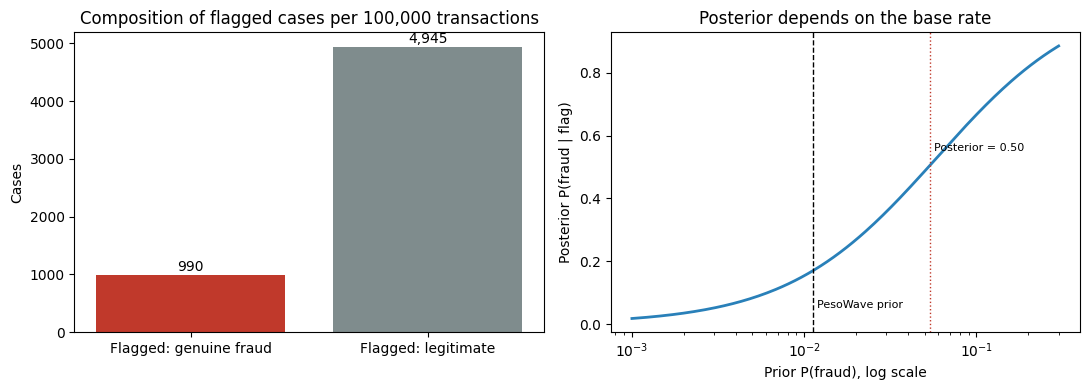


Prior where posterior first reaches 0.50: 0.0537


In [ ]:
# TODO
def bayes_posterior(prior, sensitivity, fpr):
    """P(fraud | flagged) from the prior, P(flag | fraud), and P(flag | legitimate)."""
    evidence = sensitivity * prior + fpr * (1 - prior)
    return sensitivity * prior / evidence


# By-hand inputs
print(f"Posterior (prior 1.1%, sens 0.90, FPR 0.05): {bayes_posterior(0.011, 0.90, 0.05):.4f}")

# Empirical check on the full window
emp_sens = df.loc[df["fraud"], "flagged"].mean()
emp_fpr = df.loc[~df["fraud"], "flagged"].mean()
emp_prior = df["fraud"].mean()
emp_ppv = df.loc[df["flagged"], "fraud"].mean()

print(f"\nEmpirical sensitivity        : {emp_sens:.4f}")
print(f"Empirical false-positive rate: {emp_fpr:.4f}")
print(f"Empirical prior P(F)         : {emp_prior:.4f}")
print(f"Bayes posterior from these   : {bayes_posterior(emp_prior, emp_sens, emp_fpr):.4f}")
print(f"Observed share of flags that are fraud: {emp_ppv:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Composition of the flagged pool per 100,000 transactions
tp = 100_000 * 0.011 * 0.90
fp = 100_000 * 0.989 * 0.05
axes[0].bar(["Flagged: genuine fraud", "Flagged: legitimate"], [tp, fp], color=["#c0392b", "#7f8c8d"])
for i, v in enumerate([tp, fp]):
    axes[0].text(i, v + 60, f"{v:,.0f}", ha="center")
axes[0].set_title("Composition of flagged cases per 100,000 transactions")
axes[0].set_ylabel("Cases")

# Posterior as a function of the prior
priors = np.logspace(np.log10(0.001), np.log10(0.30), 200)
posteriors = bayes_posterior(priors, 0.90, 0.05)

axes[1].plot(priors, posteriors, color="#2980b9", linewidth = 2)

# First prior where posterior reaches 0.50
cross_idx = np.where(posteriors >= 0.50)[0][0]
cross_prior = priors[cross_idx]

axes[1].axvline(cross_prior, color="#c0392b", linestyle=":", linewidth = 1)
axes[1].text(cross_prior * 1.05, 0.55,"Posterior = 0.50", fontsize = 8)
axes[1].axvline(emp_prior, color="black", linestyle="--", linewidth=1)
axes[1].text(emp_prior * 1.05, 0.05, "PesoWave prior",fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xlabel("Prior P(fraud), log scale")
axes[1].set_ylabel("Posterior P(fraud | flag)")
axes[1].set_title("Posterior depends on the base rate")
plt.tight_layout()
plt.show()

print(f"\nPrior where posterior first reaches 0.50: {cross_prior:.4f}")

**Answer — Item 3(c) interpretation**

The Bayes posterior using the validation-report values is approximately 0.1668, which matches the hand calculation. The empirical sensitivity, false-positive rate, and observed share of flagged transactions that are fraud are close to the theoretical values, indicating that the simulated data behave as expected.

The graph shows that P(F∣Fl)P(F \mid Fl)P(F∣Fl) increases as the prior fraud rate increases. When fraud is rare, even a highly sensitive model produces many false positives relative to true positives, so the posterior probability remains relatively low. As the prior fraud rate grows, a larger share of flagged transactions correspond to genuine fraud, causing the posterior to increase.

The vertical line at PesoWave's observed prior ($\approx 1.1$%) lies well below the prior required for the posterior to reach 0.50. This means that, under current conditions, a flagged transaction is more likely to be legitimate than fraudulent. Therefore, the usefulness of a flag depends not only on the model's sensitivity and false-positive rate but also on the underlying prevalence of fraud in the transaction population.

## Section 2: Business Context & Reasoning

*Two stakeholder problems, 15 points each (30 points in total). In each problem, part (a) is worth 3 points, part (b) 6 points, and part (c) 6 points. Parts (a) and (b) are assessed for technical soundness; part (c) is assessed for business reasoning. Work that is technically correct but yields a recommendation that ignores the operating context, and work with a sensible recommendation built on incorrect probabilities, both fall short of full marks.*

### Item 4 (15 pts): Choosing a model operating point under limited review capacity

Trina must choose between two operating points for the fraud model next month. Treat Window B as a representative month of 45,000 transactions, with a fraud rate equal to the rate observed in `df`.

| Option | Sensitivity | False-positive rate |
|---|---|---|
| A (current threshold) | 0.90 | 0.05 |
| B (stricter threshold) | 0.80 | 0.02 |

Operating facts: each manual review of a flagged case costs ₱95; each fraud that is not stopped costs ₱18,500 on average; analysts can open at most 1,800 flagged cases per month. Flagged cases are opened in random order until capacity is reached. A fraud in an opened case is stopped. Flagged cases beyond capacity are released, and any fraud among them is lost, as is every fraud the model fails to flag. Total cost is the review cost of the opened cases plus the loss from frauds that are not stopped.

**(a) Assumption (3 pts).** State one assumption, beyond those given above, on which your comparison depends, and explain briefly why it is reasonable for PesoWave.

**(b) Technique and interpretation (6 pts).** For each option, compute the expected number of flagged cases, the expected number of genuine frauds among them, the posterior $P(F \mid \text{Fl})$, the number of cases opened, the number of frauds stopped and not stopped, and the total cost. Interpret in two or three sentences why the two options differ in the share of flagged cases that are fraud.

**(c) Recommendation (6 pts).** Write a recommendation to Trina (150 words or fewer) that states which option you would adopt, addresses the capacity constraint, and names one risk or follow-up action.

**Answer — Item 4(a)**

The fraud rate observed in df is representative of the fraud rate next month. This assumption is necessary because the projected numbers of fraudulent transactions, flagged transactions, and total costs are all computed using the fraud rate observed in Window B. It is reasonable for PesoWave because the problem states that Window B should be treated as a representative month of 45,000 transactions, suggesting that next month's transaction behavior is expected to be similar to the observed period.


**Answer — Item 4(b) computation**

In [48]:
# TODO

N = 45_000
capacity = 1_800
review_cost = 95
fraud_loss = 18_500

def operating_summary(sens, fpr, label):
    fraud_cases = N * p_F
    legit_cases = N * (1 - p_F)
    tp = sens * fraud_cases
    fp = fpr * legit_cases
    flagged_pool = tp + fp
    posterior = tp / flagged_pool
    opened = min(capacity, flagged_pool)
    frauds_stopped = opened * posterior
    frauds_not_stopped = fraud_cases - frauds_stopped
    total_cost = (opened * review_cost + frauds_not_stopped * fraud_loss)
    return {"Option": label, "Flagged cases": flagged_pool, "Genuine frauds among flagged": tp, "P(F|Fl)": posterior, 
            "Cases opened": opened, "Frauds stopped": frauds_stopped, "Frauds not stopped": frauds_not_stopped,
            "Total cost": total_cost}

summary = pd.DataFrame([operating_summary(0.90, 0.05, "A"),
                        operating_summary(0.80, 0.02, "B")]).set_index("Option")

print(summary.round(2).to_string())

        Flagged cases  Genuine frauds among flagged  P(F|Fl)  Cases opened  Frauds stopped  Frauds not stopped  Total cost
Option                                                                                                                    
A             2682.65                         458.1     0.17       1800.00          307.38              201.62  3901059.35
B             1297.02                         407.2     0.31       1297.02          407.20              101.80  2006516.90


**Answer — Item 4(b) interpretation and 4(c) recommendation**

Option B has a higher P(F∣Fl)P(F \mid Fl)P(F∣Fl) because its lower false-positive rate means that fewer legitimate transactions are flagged. As a result, a larger proportion of flagged cases are genuine frauds, even though the model detects a smaller fraction of all frauds due to its lower sensitivity. In contrast, Option A catches more frauds but also flags many more legitimate transactions, reducing the share of flagged cases that are actually fraudulent.

I recommend adopting Option B. Although Option B has lower sensitivity (0.80 versus 0.90), it generates far fewer flagged cases (about 1,297 versus 2,683), allowing all flagged cases to be reviewed within the 1,800-case monthly capacity. In contrast, Option A exceeds the review limit, leaving some flagged cases unreviewed and resulting in additional fraud losses. Option B also has a higher P(F∣Fl)P(F \mid Fl)P(F∣Fl) (0.31 versus 0.17), meaning that a larger proportion of reviewed cases are genuine frauds. Most importantly, Option B produces the lower expected total cost (approximately ₱2.01 million versus ₱3.90 million for Option A). One risk is that the fraud rate or model performance may change over time. As a follow-up action, PesoWave should monitor monthly fraud prevalence, review capacity utilization, and model accuracy to ensure that Option B remains the most cost-effective choice.

### Item 5 (15 pts): Routing flagged cases using a sequential update

PesoWave routes each flagged transaction using the probability that it is fraud after the model flag and the step-up OTP result: a posterior of 0.60 or higher is placed on an automatic hold; a posterior of 0.05 or lower is released automatically; anything in between joins the analyst queue. The model has sensitivity 0.90 and false-positive rate 0.05. The OTP challenge is failed by 75% of fraudulent attempts and 6% of legitimate ones. Use the observed fraud rate of each channel-by-device segment in `df` as the prior for that segment.

Three flagged transactions arrive:

- **Case 1:** App Transfer, new device, OTP failed.
- **Case 2:** QR Merchant Payment, established device, OTP passed.
- **Case 3:** Cash-In, established device, OTP failed.

**(a) Assumption (3 pts).** The sequential update treats the model flag and the OTP result as conditionally independent given the fraud status. State this assumption in your own words and explain one realistic way it could fail at PesoWave.

**(b) Technique and interpretation (6 pts).** Compute the segment prior, the posterior after the flag, and the posterior after the OTP result for each case. Compare each final posterior with the observed share of fraud among flagged cases in `df` with the same segment and OTP outcome, and comment on any gap, including how many cases lie behind each observed figure.

**(c) Recommendation (6 pts).** State the routing (automatic hold, analyst queue, or automatic release) for each case and justify it. Then recommend one safeguard for customers who are legitimately held, and one metric Trina should monitor to confirm the routing rule is working.

**Answer — Item 5(a)**

The conditional independence assumption means that once we know whether a transaction is fraudulent or legitimate, the model flag and the OTP result are treated as separate pieces of information. In other words, after accounting for the fraud status, the chance of failing the OTP challenge should not depend on whether the transaction was flagged by the model.

This assumption may not always hold at PesoWave. For example, suspicious behaviors such as logging in from a new device or making an unusual transaction could increase both the likelihood of being flagged by the model and the likelihood of failing the OTP challenge. In that case, the flag and OTP result would still be related even after considering the fraud status, which could cause the sequential update to overestimate or underestimate the true probability of fraud.

**Answer — Item 5(b) computation**

In [9]:
# TODO

**Answer — Item 5(b) interpretation and 5(c) recommendation**

## Citation Reminder

All external sources used in this assignment (textbooks, papers, articles, code snippets, and any use of generative AI tools) must be cited in accordance with the course citation policy. Add each additional source you use to the References section below.

## References

Blitzstein, J. K., & Hwang, J. (2019). *Introduction to Probability* (2nd ed.). CRC Press.

Gigerenzer, G., & Hoffrage, U. (1995). How to improve Bayesian reasoning without instruction: Frequency formats. *Psychological Review, 102*(4), 684-704.

Ross, S. M. (2019). *A First Course in Probability* (10th ed.). Pearson.

Wasserman, L. (2004). *All of Statistics: A Concise Course in Statistical Inference*. Springer.